In [8]:
import pandas as pd
import numpy as np

# --- 1. Load the original CSV file ---
# Make sure 'no2_essen_2025-08_11_raw.csv' is in the same folder as this script/notebook.
df = pd.read_csv('no2_essen_2025-08_11_raw.csv')

In [9]:
# --- 2. Data Cleaning and Preparation ---

# Convert the time column to datetime objects and set it as the index
df['datetime_from_utc'] = pd.to_datetime(df['datetime_from_utc'])
df = df.set_index('datetime_from_utc').sort_index()

# Select only the target variable ('value') for cleaning and feature engineering
df_clean = df[['value']].copy()

# Note: In the previous step, we confirmed there were no missing values in 'value'.
# If there were, the imputation step would go here:
# df_clean['value'].fillna(method='ffill', inplace=True) # Forward-fill imputation
df_clean.head()

,value
datetime_from_utc,
2024-01-01 00:00:00+00:00,5.816
2024-01-01 01:00:00+00:00,3.816
2024-01-01 02:00:00+00:00,2.329
2024-01-01 03:00:00+00:00,1.464
2024-01-01 04:00:00+00:00,2.096


In [10]:
df_clean.isnull().values.any()

np.False_

In [11]:
df_clean.isnull().sum()
#Just in case i want to check for my satisfaction, if there are any null values in column.

value    0
dtype: int64

In [31]:
# --- 3. Feature Engineering: Temporal Features ---
# Extract features that capture time-based patterns (daily, weekly, yearly)
df_clean['Hour'] = df_clean.index.hour
df_clean['DayOfWeek'] = df_clean.index.dayofweek # 0=Monday, 6=Sunday
df_clean['Month'] = df_clean.index.month

In [32]:
df.head()

,value,parameter,units,datetime_to_utc,location_id,location_name,sensor_id
datetime_from_utc,,,,,,,
2024-01-01 00:00:00+00:00,5.816,no2,µg/m³,2024-01-01T01:00:00Z,3063,Essen-Ost Steeler Straße,6516
2024-01-01 01:00:00+00:00,3.816,no2,µg/m³,2024-01-01T02:00:00Z,3063,Essen-Ost Steeler Straße,6516
2024-01-01 02:00:00+00:00,2.329,no2,µg/m³,2024-01-01T03:00:00Z,3063,Essen-Ost Steeler Straße,6516
2024-01-01 03:00:00+00:00,1.464,no2,µg/m³,2024-01-01T04:00:00Z,3063,Essen-Ost Steeler Straße,6516
2024-01-01 04:00:00+00:00,2.096,no2,µg/m³,2024-01-01T05:00:00Z,3063,Essen-Ost Steeler Straße,6516


In [33]:
# --- 4. Feature Engineering: Time-Lagged Features ---
# This transforms the time-series problem into a supervised learning problem.
# It uses past values of NO2 to predict the current/future value.
for lag in [1, 6, 24]:
    df_clean[f'lag_{lag}h'] = df_clean['value'].shift(lag)


In [34]:
# The first 24 rows will now have NaN values due to the 24-hour lag.
# We drop these rows as they are incomplete training examples.
df_clean.dropna(inplace=True)

In [35]:
# --- 5. Save the Final Data Corpus ---
clean_file_name = 'no2_essen_cleaned_for_ml.csv'
df_clean.to_csv(clean_file_name)

print(f"Data cleaning and feature engineering complete.")
print(f"The final model-ready data corpus is saved as: {clean_file_name}")
print(f"Total observations for ML training: {len(df_clean)} rows.")
print("\nFirst 5 rows of the cleaned data (showing engineered features):")
print(df_clean.head())

Data cleaning and feature engineering complete.
The final model-ready data corpus is saved as: no2_essen_cleaned_for_ml.csv
Total observations for ML training: 13594 rows.

First 5 rows of the cleaned data (showing engineered features):
                            value  Hour  DayOfWeek  Month  lag_1h  lag_6h  \
datetime_from_utc                                                           
2024-01-02 04:00:00+00:00   3.013     4          1      1   1.463  10.672   
2024-01-02 05:00:00+00:00   4.674     5          1      1   3.013   8.858   
2024-01-02 06:00:00+00:00   8.336     6          1      1   4.674   4.358   
2024-01-02 08:00:00+00:00   9.422     8          1      1   8.336   4.042   
2024-01-02 09:00:00+00:00  11.958     9          1      1   9.422   2.210   

                           lag_24h  
datetime_from_utc                   
2024-01-02 04:00:00+00:00    5.816  
2024-01-02 05:00:00+00:00    3.816  
2024-01-02 06:00:00+00:00    2.329  
2024-01-02 08:00:00+00:00    1.464  
2

In [45]:
df_clean.head()

,value,Hour,DayOfWeek,Month,lag_1h,lag_6h,lag_24h
datetime_from_utc,,,,,,,
2024-01-02 04:00:00+00:00,3.013,4,1,1,1.463,10.672,5.816
2024-01-02 05:00:00+00:00,4.674,5,1,1,3.013,8.858,3.816
2024-01-02 06:00:00+00:00,8.336,6,1,1,4.674,4.358,2.329
2024-01-02 08:00:00+00:00,9.422,8,1,1,8.336,4.042,1.464
2024-01-02 09:00:00+00:00,11.958,9,1,1,9.422,2.210,2.096


In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV file and prepare for EDA (replicate cleaning steps)
df = pd.read_csv('no2_essen_2025-08_11_raw.csv')
df['datetime_from_utc'] = pd.to_datetime(df['datetime_from_utc'])
df = df.set_index('datetime_from_utc').sort_index()
df_eda = df[['value']].copy()


In [37]:
# Feature Engineering for EDA plots
df_eda['Hour'] = df_eda.index.hour
df_eda['DayOfWeek'] = df_eda.index.dayofweek # 0=Monday, 6=Sunday
df_eda['Month'] = df_eda.index.month

In [38]:
# --- 1. Aggregating Data ---
hourly_avg = df_eda.groupby('Hour')['value'].mean()
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekly_avg = df_eda.groupby('DayOfWeek')['value'].mean().rename(lambda x: day_names[x])
monthly_avg = df_eda.groupby('Month')['value'].mean()


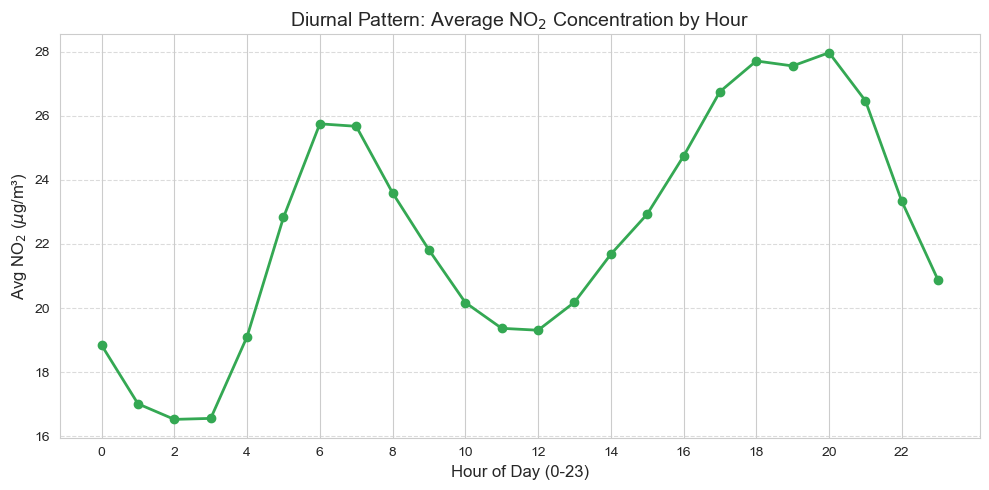

In [39]:
# --- 2. Generating LARGE, Clear Plots ---
sns.set_style("whitegrid")

# Plot A: Diurnal Pattern (Large)
plt.figure(figsize=(10, 5))
hourly_avg.plot(kind='line', marker='o', color='#34A853', linewidth=2)
plt.title('Diurnal Pattern: Average NO$_2$ Concentration by Hour', fontsize=14)
plt.xlabel('Hour of Day (0-23)', fontsize=12)
plt.ylabel('Avg NO$_2$ ($\mu$g/m³)', fontsize=12)
plt.xticks(range(0, 24, 2)) # Show every 2 hours for clarity
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

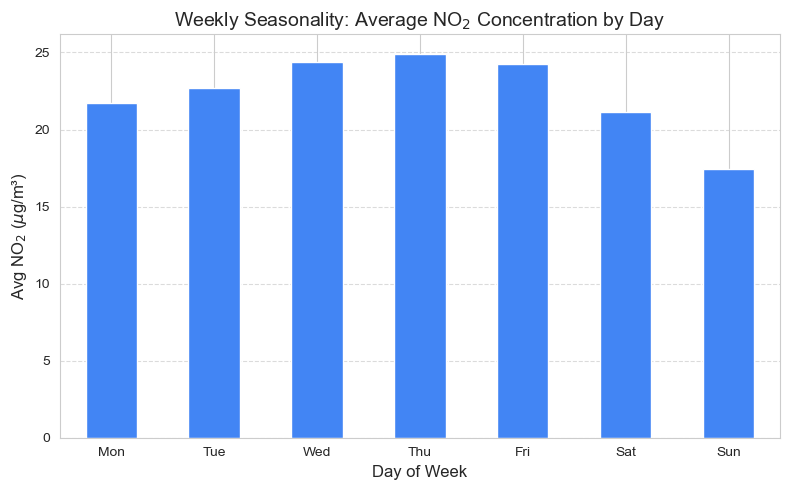

In [40]:
# Plot B: Weekly Seasonality (Large Bar Chart)
plt.figure(figsize=(8, 5))
weekly_avg.plot(kind='bar', color='#4285F4')
plt.title('Weekly Seasonality: Average NO$_2$ Concentration by Day', fontsize=14)
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Avg NO$_2$ ($\mu$g/m³)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

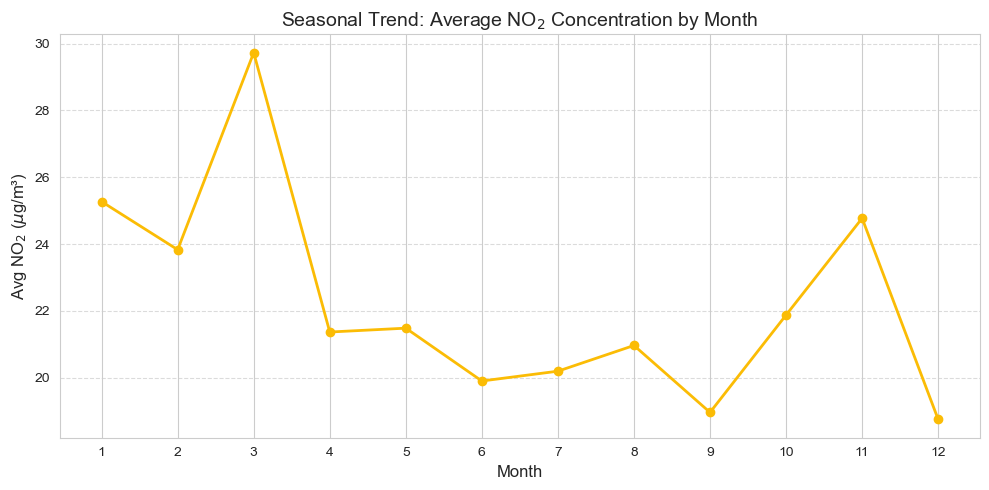

In [41]:
# Plot C: Seasonal Trend (Large)
plt.figure(figsize=(10, 5))
monthly_avg.plot(kind='line', marker='o', color='#FBBC05', linewidth=2)
plt.title('Seasonal Trend: Average NO$_2$ Concentration by Month', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Avg NO$_2$ ($\mu$g/m³)', fontsize=12)
plt.xticks(range(1, 13))
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 0. Load and prepare data (same as you used)
df = pd.read_csv('no2_essen_2025-08_11_raw.csv')
df['datetime_from_utc'] = pd.to_datetime(df['datetime_from_utc'])
df = df.set_index('datetime_from_utc').sort_index()

df_eda = df[['value']].copy()
df_eda['Hour'] = df_eda.index.hour
df_eda['DayOfWeek'] = df_eda.index.dayofweek        # 0=Mon
df_eda['Month'] = df_eda.index.month

# Optional: create 'Season' for boxplots
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df_eda['Season'] = df_eda['Month'].map(season_map)

sns.set_style("whitegrid")

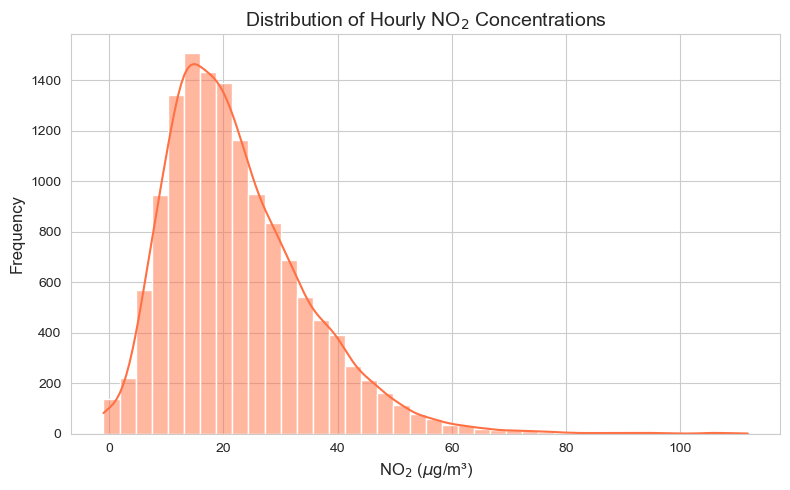

In [2]:
# 1. Distribution of NO2 (Histogram + KDE)
plt.figure(figsize=(8,5))
sns.histplot(df_eda['value'], bins=40, kde=True, color='#FF7043')
plt.title('Distribution of Hourly NO$_2$ Concentrations', fontsize=14)
plt.xlabel('NO$_2$ ($\\mu$g/m³)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()
plt.show()

/var/folders/ms/yhbvtkx53qqdv9h0yjbjtmy40000gn/T/ipykernel_21042/4091051487.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Season', y='value', data=df_eda,


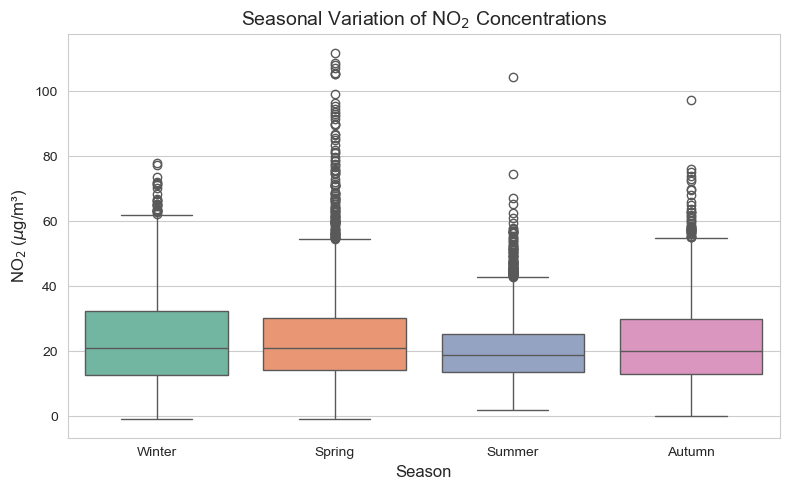

In [3]:
# 2. Boxplot by season
plt.figure(figsize=(8,5))
sns.boxplot(x='Season', y='value', data=df_eda,
            order=['Winter', 'Spring', 'Summer', 'Autumn'],
            palette='Set2')
plt.title('Seasonal Variation of NO$_2$ Concentrations', fontsize=14)
plt.xlabel('Season', fontsize=12)
plt.ylabel('NO$_2$ ($\\mu$g/m³)', fontsize=12)
plt.tight_layout()
plt.show()

/var/folders/ms/yhbvtkx53qqdv9h0yjbjtmy40000gn/T/ipykernel_21042/2188496115.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DayName', y='value', data=df_eda,


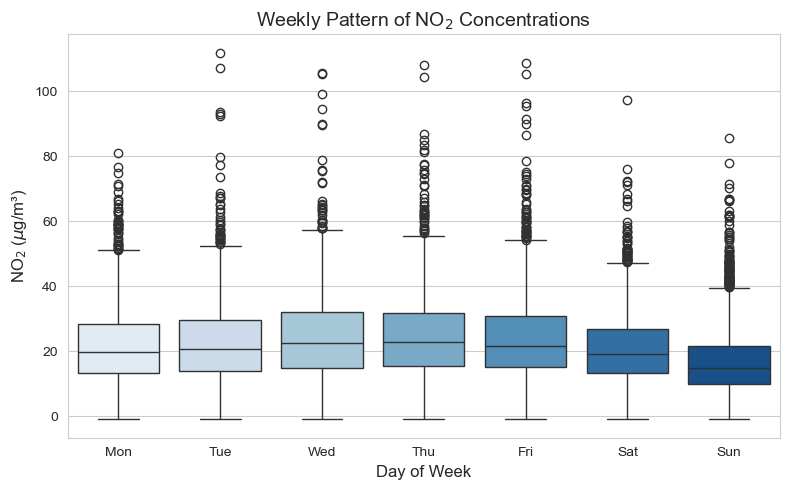

In [4]:
# 3. Boxplot by day of week
day_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df_eda['DayName'] = df_eda['DayOfWeek'].map(dict(enumerate(day_names)))

plt.figure(figsize=(8,5))
sns.boxplot(x='DayName', y='value', data=df_eda,
            order=day_names, palette='Blues')
plt.title('Weekly Pattern of NO$_2$ Concentrations', fontsize=14)
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('NO$_2$ ($\\mu$g/m³)', fontsize=12)
plt.tight_layout()
plt.show()

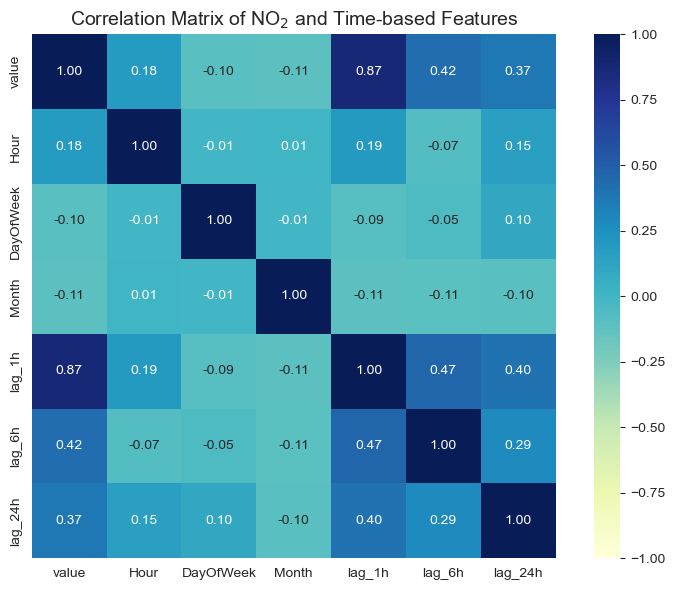

In [5]:
# 4. Correlation heatmap (using ML-ready features)
df_ml = pd.read_csv('no2_essen_cleaned_for_ml.csv')
corr = df_ml[['value', 'Hour', 'DayOfWeek', 'Month',
              'lag_1h', 'lag_6h', 'lag_24h']].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='YlGnBu', vmin=-1, vmax=1,
            fmt='.2f', square=True)
plt.title('Correlation Matrix of NO$_2$ and Time-based Features', fontsize=14)
plt.tight_layout()
plt.show()